# Analisis Kepadatan dan Klasifikasi Kendaraan pada Lalu Lintas

Hanafi Khairul Shiddiq · Naila Syakira · Helena Koronka Innarmastia · Gilbard Kinan Nangwaya · Tenno Cahyo Berliantoko  
Pengolahan Citra Digital · Universitas Gadjah Mada

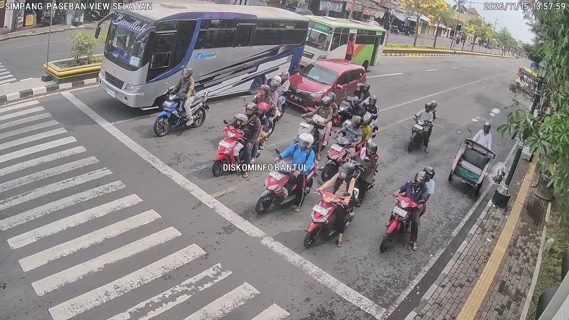

*Antrean di Paseban Selatan, Bantul (S033). Sumber foto: Diskominfo Bantul.*

**Jika jumlah kendaraan tepat, apakah luas jalan yang tertutup juga tepat?** Kami menguji dua keluaran dari satu foto CCTV: jumlah mobil, motor, bus, dan truk, serta persentase area jalan (ROI) yang tertutup gabungan kotak kendaraan. ROI membentang dari batas henti hingga batas belakang yang ditentukan pada setiap sudut kamera.

Semua tabel dan gambar hasil tersimpan di sini. Untuk menghitung ulang tanpa mengunduh data, buka berkas ini di Jupyter dengan Python 3.12, NumPy, Pillow, Matplotlib, dan OpenCV dengan HOG (paket rujukan `opencv-contrib-python-headless==5.0.0.93`), lalu pilih *Restart Kernel and Run All*. Mode `bukti` memakai prediksi tersimpan; mode `inferensi` menjalankan v45 dengan interpreter Python kernel. Salinan pengumpulan menyimpan hasil inferensi baru. Menjalankan ulang dengan pengaturan bawaan memeriksa bukti tersimpan.

In [1]:
# Untuk inferensi, siapkan model sekali melalui src/v45/siapkan_model.py.
import base64, csv, hashlib, io, json, os, subprocess, sys, tempfile
from collections import Counter
from html import escape
from pathlib import Path
from zipfile import ZipFile
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle
from PIL import Image
from IPython.display import HTML, Image as GambarNotebook, display

MODE = os.environ.get("BANTUL_MODE", "bukti")
lokasi_demo = [Path("src/v45"), Path("../src/v45")]
PAKET = next((p for p in lokasi_demo if (p / "demo.py").is_file()), lokasi_demo[0])
PAKET = Path(os.environ.get("BANTUL_PAKET", PAKET)).expanduser().resolve()
FOTO_BARU, KAMERA = None, None  # Mode inferensi: isi path foto dan ID kamera aslinya.
SEMUA_ITERASI, ULANG_BASELINE = False, False
KELAS = ("mobil", "motor", "bus", "truk")
if MODE not in {"bukti", "inferensi"} or (FOTO_BARU and MODE != "inferensi"):
    raise ValueError("Pilih bukti atau inferensi. Foto baru memerlukan mode inferensi.")
if MODE == "inferensi" and not (PAKET / "demo.py").is_file():
    raise FileNotFoundError("Isi PAKET dengan folder src/v45 dari repo tugas akhir.")

def buka_bukti():
    lokasi = os.environ.get("BANTUL_NOTEBOOK")
    nama = "analisis_kepadatan_bantul.ipynb"
    calon = [Path(lokasi)] if lokasi else [Path.cwd()/nama, Path.cwd()/"notebooks"/nama]
    for path in calon:
        if not path.is_file():
            continue
        meta = json.loads(path.read_bytes()).get("metadata", {}).get("bantul_v45", {})
        if meta.get("sha256") == "71db23089c6538752eff920a282144951cb935ec018856ce0f0e1196f3257d4d":
            data = base64.b64decode(meta["archive"], validate=True)
            if hashlib.sha256(data).hexdigest() != meta["sha256"]:
                raise ValueError("Checksum data pendamping berbeda.")
            return ZipFile(io.BytesIO(data))
    raise FileNotFoundError("Buka dari folder notebook atau isi BANTUL_NOTEBOOK dengan path berkas ini.")

bukti = buka_bukti()
def baca(nama):
    return json.loads(bukti.read(nama))
def baris_csv(nama):
    return list(csv.DictReader(io.StringIO(bukti.read(nama).decode("utf-8-sig"))))
def gambar(nama):
    return np.array(Image.open(io.BytesIO(bukti.read(nama))).convert("RGB"))
def angka(x, n=2):
    return f"{x:,.{n}f}".translate(str.maketrans(".,", ",."))
def tabel(kolom, baris):
    def deret(tag, nilai):
        return "<tr>" + "".join(f"<{tag}>{escape(str(v))}</{tag}>" for v in nilai) + "</tr>"
    display(HTML("<table><thead>" + deret("th", kolom) + "</thead><tbody>" +
                 "".join(deret("td", row) for row in baris) + "</tbody></table>"))

acuan_demo, rois = baca("acuan_demo.json"), baca("ROIS.json")
foto_s033 = gambar("S033.jpg")
assert hashlib.sha256(bukti.read("S033.jpg")).hexdigest() == acuan_demo["S033"]["image_sha256"]
print(f"v45 · {MODE} · S033 / Paseban Selatan · sumber data pendamping terverifikasi")
print("Asal prediksi:", "dihitung kembali dengan model rilis" if MODE == "inferensi" else "rekaman keluaran v45")

v45 · inferensi · S033 / Paseban Selatan · sumber data pendamping terverifikasi
Asal prediksi: dihitung kembali dengan model rilis


## 1. Dari rekaman ke data siap latih

Saat kami memeriksa gambar utuh dari MIO-TCD, kotak kendaraan tersedia tetapi batas antrean di persimpangan sering tidak terlihat. Lima preset kamera membantu memilih sudut yang menampilkan garis henti dan lebar pendekat. Gambar penelitian diambil dari kamera nyata. Dua sudut Paseban melihat simpang yang sama sehingga satu kendaraan dapat muncul di dua kamera.

Pada 15 November, pengambilan setiap lima detik selama sepuluh menit menghasilkan 513 foto. Banyak foto masih memperlihatkan antrean yang sama. Pada jendela 120 menit, segmen sumber disimpan dan pratinjau dibuat sekitar tiap 20 detik. Kurasi mengelompokkan kejadian yang sama, mempertahankan pergantian antrean, dan menyertakan contoh ROI kosong. Pada 17 November, pengambilan terarah memakai interval berbeda per kamera untuk mencari contoh langka. Sesudah pembersihan arsip, asal gambar terpilih tetap bisa ditelusuri melalui manifest, waktu sumber, dan hash. [Manifest dan catatan penyimpanan](https://github.com/hanafishiddiq/tugas-akhir-pcd/tree/188efdd9c162aa071be6e67d1543273c245bbea2/data/bantul-20261115) · [CCTV Kabupaten Bantul](https://bantulkab.go.id/cctv.html) · [Lisensi CC BY 4.0 yang tercatat saat akuisisi](https://creativecommons.org/licenses/by/4.0/)

In [2]:
# Berapa banyak gambar yang benar-benar tersedia dari tiap sudut?
awal, sesi = baca("awal.json"), baca("akuisisi.json")
def nama_kamera(kode):
    return kode.split("_", 1)[1].replace("_", " ").title()
peran = {"01": "Foto utuh", "02": "Foto utuh", "03": "Cadangan; batas henti terpotong",
         "04": "Foto utuh", "05": "Potongan tambahan untuk klasifikasi TRAIN"}
daftar = []
for kamera in sesi:
    kode = kamera["camera_id"]
    daftar.append([nama_kamera(kode), awal[kode], angka(kamera["source_coverage_in_window_seconds"]/60),
                   kamera["review_sample_count"], peran[kode[:2]]])
tabel(["Sudut CCTV", "Foto awal", "Menit tersedia / 120", "Pratinjau", "Pemakaian"], daftar)
print(f"{sum(awal.values())} foto awal dan {angka(sum(k['review_sample_count'] for k in sesi), 0)} pratinjau. Satu antrean dapat muncul pada banyak foto.")

Sudut CCTV,Foto awal,Menit tersedia / 120,Pratinjau,Pemakaian
Paseban Selatan,33,"73,10",296,Foto utuh
Paseban Barat,120,"118,74",329,Foto utuh
Klodran Selatan,120,"119,34",345,Cadangan; batas henti terpotong
Bejen Barat,120,"75,08",223,Foto utuh
Palbapang Selatan,120,"119,36",357,Potongan tambahan untuk klasifikasi TRAIN


513 foto awal dan 1.550 pratinjau. Satu antrean dapat muncul pada banyak foto.


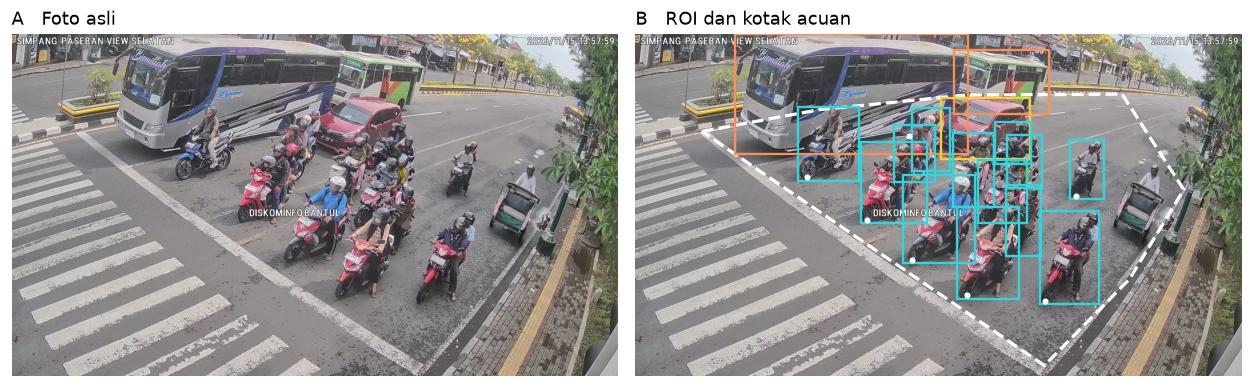

26 foto percobaan → 38 pilihan awal batch panjang → 222 foto beranotasi.
2.087 kotak termasuk konteks. Acuan hitungan lengkap: 87 foto; parsial: 135.
Kelas kotak: mobil kuning, motor sian, bus jingga, truk ungu. Garis putus-putus: batas ROI.
Pada bus depan yang atapnya terpotong, kontak ban membantu menempatkan bus di jalan sasaran.


In [3]:
# Kotak acuan S033. Titik putih menunjukkan kontak jalan jika terlihat oleh peninjau.
label = baca("label_S033.json")
ukur = label["metrics"]
objek = [o for o in label["objects"] if o["id"] in ukur["accepted_object_ids"]]
warna = dict(mobil="#ffcc29", motor="#29d8e0", bus="#ff8e55", truk="#d995ff")
def tampil_foto(ax, rgb, judul, roi=None, kotak=()):
    ax.imshow(rgb)
    if roi:
        ax.add_patch(Polygon(roi["polygon_xy"], fill=False, edgecolor="#ffffff", lw=2, ls="--"))
    for o in kotak:
        x, y, kanan, bawah = o["bbox_xyxy"]
        ax.add_patch(Rectangle((x, y), kanan-x, bawah-y, fill=False,
                               edgecolor=warna[o["class_name"]], lw=1.45))
    ax.set_title(judul, loc="left", fontsize=11)
    ax.set_axis_off()
def selesai(fig):
    fig.tight_layout()
    buf = io.BytesIO()
    format_gambar = "jpeg" if any(ax.images for ax in fig.axes) else "png"
    fig.savefig(buf, format=format_gambar, dpi=115, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(GambarNotebook(data=buf.getvalue(), format=format_gambar))

roi_s033 = rois[label["camera_id"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tampil_foto(ax[0], foto_s033, "A   Foto asli")
tampil_foto(ax[1], foto_s033, "B   ROI dan kotak acuan", roi_s033, objek)
for o in objek:
    if o["road_contact_xy"]:
        ax[1].plot(*o["road_contact_xy"], "wo", markersize=2.8)
selesai(fig)
kurasi = baca("kurasi.json")
print(f"26 foto percobaan → {kurasi['awal_38']} pilihan awal batch panjang → {kurasi['aktif']} foto beranotasi.")
print(f"{angka(kurasi['kotak'],0)} kotak termasuk konteks. Acuan hitungan lengkap: {kurasi['lengkap']} foto; parsial: {kurasi['parsial']}.")
print("Kelas kotak: mobil kuning, motor sian, bus jingga, truk ungu. Garis putus-putus: batas ROI.")
print("Pada bus depan yang atapnya terpotong, kontak ban membantu menempatkan bus di jalan sasaran.")

In [4]:
# Seluruh crop mengikuti kelompok foto asal, termasuk pasangan pandangan dari simpang yang sama.
sampel = baca("split.json")
inti = [x for x in sampel if x["peran"] != "auxiliary_classification_train_only"]
tambahan = [x for x in sampel if x["peran"] == "auxiliary_classification_train_only"]
himpunan = ("train", "validation", "test")
grup = {s: {x["grup"] for x in inti if x["split"] == s} for s in himpunan}
assert all(grup[a].isdisjoint(grup[b]) for i, a in enumerate(himpunan) for b in himpunan[i+1:])
assert all(x["split"] == "train" for x in tambahan)
n_split = Counter(x["split"] for x in inti)
tabel(["Bagian pilot", "Foto inti"], [(s, n_split[s]) for s in (*himpunan, "embargo", "quarantine")])
print(f"{len(inti)} foto inti. Tambahan {len(tambahan)} foto Palbapang khusus klasifikasi latih.")
print(f"Kelompok uji: {len(grup['test'])}. Irisan kelompok antarbagian aktif: 0.")
print("Anotasi dan pemeriksaan silang dibantu AI. Objek meragukan diberi tanda ignore; acuan parsial tidak dipakai untuk galat hitungan atau luas.")

Bagian pilot,Foto inti
train,99
validation,61
test,76
embargo,10
quarantine,2


248 foto inti. Tambahan 12 foto Palbapang khusus klasifikasi latih.
Kelompok uji: 55. Irisan kelompok antarbagian aktif: 0.
Anotasi dan pemeriksaan silang dibantu AI. Objek meragukan diberi tanda ignore; acuan parsial tidak dipakai untuk galat hitungan atau luas.


## 2. Dari contoh latih ke prediksi satu foto

Potongan kendaraan dari **TRAIN** menjadi contoh positif. Latar jalan dan fragmen yang pernah salah dikenali menjadi contoh negatif. Setiap kandidat dipindai di beberapa skala dan rasio. HOG merangkum arah tepi; warna, tekstur, selisih terhadap latar latih, ukuran, dan posisi kandidat melengkapi cirinya. SVM memberi skor kelas dan penilai berbasis pohon memperkirakan mutu lokasi. Regresi memperbaiki tepi kotak, lalu kandidat yang saling bertumpuk digabung atau disaring. Pada v45, koreksi halus kotak motor dan pemeriksaan fragmen memperbaiki hasil validasi. Seluruh detektor memakai pengolahan citra dan pembelajaran mesin klasik.

Berikut satu mobil pada S033. Potongan **validasi** ini memperlihatkan apa yang dilihat ekstraktor HOG. Contoh pelatihan, latar referensi, dan penyesuaian fitur diambil dari sisi latih; ambang deteksi dipilih pada validasi.

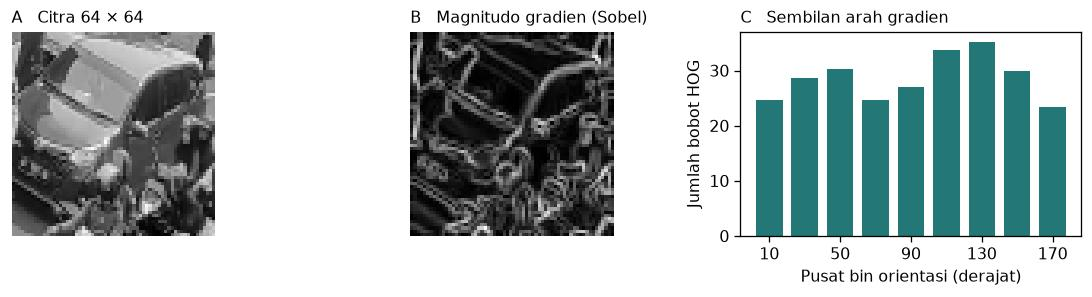

1764 nilai HOG: 7 × 7 posisi blok, 4 sel per blok, 9 arah per sel.


In [5]:
# Deskriptor yang sama dengan vision.HOG proyek. Histogram menjumlahkan bobot dari semua blok.
mobil = next(o for o in objek if o["class_name"] == "mobil")
x1, y1, x2, y2 = mobil["bbox_xyxy"]
abu = cv2.cvtColor(foto_s033, cv2.COLOR_RGB2GRAY)
tile = cv2.resize(abu[y1:y2, x1:x2], (64, 64), interpolation=cv2.INTER_AREA)
hog = cv2.HOGDescriptor(_winSize=(64,64), _blockSize=(16,16), _blockStride=(8,8),
                        _cellSize=(8,8), _nbins=9, _gammaCorrection=True)
fitur = hog.compute(tile).ravel()
assert fitur.size == hog.getDescriptorSize() == 1764
gx = cv2.Sobel(tile, cv2.CV_32F, 1, 0)
gy = cv2.Sobel(tile, cv2.CV_32F, 0, 1)
fig, ax = plt.subplots(1, 3, figsize=(10.2, 2.7))
for a, im, judul in [(ax[0], tile, "A   Citra 64 × 64"), (ax[1], np.hypot(gx, gy), "B   Magnitudo gradien (Sobel)")]:
    a.imshow(im, cmap="gray", interpolation="nearest"); a.set_title(judul, loc="left", fontsize=10); a.axis("off")
ax[2].bar(np.arange(10,180,20), fitur.reshape(-1,9).sum(axis=0), width=15, color="#247777")
ax[2].set(xlabel="Pusat bin orientasi (derajat)", ylabel="Jumlah bobot HOG", xticks=[10,50,90,130,170])
ax[2].set_title("C   Sembilan arah gradien", loc="left", fontsize=10)
selesai(fig)
print(f"{fitur.size} nilai HOG: 7 × 7 posisi blok, 4 sel per blok, 9 arah per sel.")

In [6]:
# Seluruh 45 catatan ada dalam berkas. Pilih keluaran global tonggak, bukan cabang dengan skor tertinggi.
register = baca("eksperimen.json")
urutan = {x["versi"]: x for x in register}
akhiran = {1: "/evaluation/VALIDATION_METRICS.json", 10: "/calibrated/evaluation/VALIDATION_METRICS.json",
           35: "/evaluation/VALIDATION_METRICS.json", 45: "/evaluation/VALIDATION_METRICS.json"}
perubahan = {1: "HOG + SVM awal, sesudah kalibrasi", 10: "SVM dengan fitur tambahan",
             35: "Tambahan positif untuk penilai lokasi truk", 45: "Koreksi halus kotak motor dan pemeriksa fragmen"}
def f1_validasi(v):
    cocok = [e["macro_f1"] for e in urutan[v]["evaluasi"] if e["run"].endswith(akhiran[v])]
    assert len(cocok) == 1
    return cocok[0]
tabel(["Versi", "Perubahan yang diuji", "Macro-F1 validasi"], [
    (f"v{v}", perubahan[v], angka(100*f1_validasi(v))+"%") for v in perubahan])
print(f"{len(register)} iterasi tercatat. Angka di tabel berasal dari validasi gambar utuh yang sama.")
if SEMUA_ITERASI:
    for e in register:
        skor = ", ".join(f"{s['run']} = {angka(100*s['macro_f1'])}%" for s in e["evaluasi"])
        print(f"v{e['versi']} · {e['judul']}\n  {e['catatan']}\n  {skor or 'Lihat catatan percobaan.'}")

if ULANG_BASELINE:
    # Isi BANTUL_WORKSPACE dengan root pengembangan lengkap. Run baru tidak menimpa eksperimen lama.
    root_latih = Path(os.environ["BANTUL_WORKSPACE"]).resolve()
    kode = root_latih / "Jawaban/Perencanaan_Baseline/Tahap_04/kode"
    keluaran = Path(tempfile.mkdtemp(prefix="ulangan-v1-", dir=kode.parent))
    for fase in ("prepare", "fit", "evaluate"):
        subprocess.run([sys.executable, "-B", "experiment.py", "--root", str(root_latih),
                        "--output", str(keluaran), "--phase", fase], cwd=kode, check=True)
    print("Hasil baseline lokal:", keluaran)

Versi,Perubahan yang diuji,Macro-F1 validasi
v1,"HOG + SVM awal, sesudah kalibrasi","7,33%"
v10,SVM dengan fitur tambahan,"60,40%"
v35,Tambahan positif untuk penilai lokasi truk,"84,91%"
v45,Koreksi halus kotak motor dan pemeriksa fragmen,"85,50%"


45 iterasi tercatat. Angka di tabel berasal dari validasi gambar utuh yang sama.


**Mengapa berhenti pada v45?** Skor validasi 85,50% diperoleh setelah pemilihan konfigurasi berulang. V45 dan pembanding v35 dibekukan sebelum uji resmi. Percobaan lanjutan terhadap pikap boks dan fragmen bus belum memberi perbaikan yang konsisten. Pada 11 foto siang untuk diagnosis, kandidat dan v45 masing-masing menemukan satu dari dua truk, sementara alarm palsu truk naik dari satu menjadi delapan. Skor pengenalan pada potongan kendaraan menjawab pertanyaan berbeda dari deteksi pada foto utuh, yang juga menuntut lokasi kotak benar.

Di bawah ini identitas kamera menentukan geometri jalan. Dua kamera Paseban sama-sama beresolusi 1920 × 1080. Untuk foto baru, cocokkan garis henti dan arah kamera sebelum menjalankan model. Pengulangan baseline awal memerlukan workspace latih lengkap; paket demo menyediakan inferensi v45. [Kode dan panduan rilis](https://github.com/hanafishiddiq/tugas-akhir-pcd/tree/main/docs/rilis-v45)

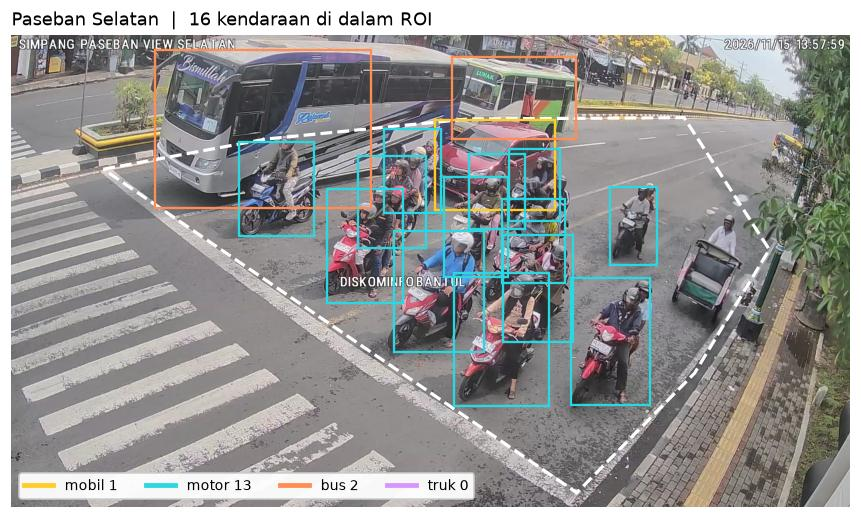

Model 9bb33935eec4e5c174b3 · inferensi · Paseban Selatan


In [7]:
# Program rilis memproses foto utuh. Dalam mode bukti, daftar prediksi berasal dari berkas beku.
def demo_baru(foto=None, kamera=None):
    with tempfile.TemporaryDirectory() as folder:
        args = ["--foto", str(Path(foto).resolve()), "--kamera", kamera] if foto else ["--contoh", "S033"]
        if foto and kamera not in rois:
            raise ValueError("Pilih ID kamera yang cocok dengan foto.")
        subprocess.run([sys.executable, "-X", "utf8", str(PAKET/"demo.py"), *args, "--hasil", folder], check=True,
                       capture_output=True)
        hasil, = Path(folder).glob("*/hasil.json")
        rekaman = json.loads(hasil.read_bytes())
        with Image.open(hasil.with_name("cakupan.png")) as mask:
            rekaman["mask_pixels_sha256"] = hashlib.sha256(mask.convert("L").tobytes()).hexdigest()
        return rekaman

hasil = demo_baru(FOTO_BARU, KAMERA) if MODE == "inferensi" else acuan_demo["S033"]
foto = np.array(Image.open(FOTO_BARU).convert("RGB")) if FOTO_BARU else foto_s033
roi = rois[hasil["camera_id"]]
diterima = [p for p in hasil["predictions"] if p["roi_membership"] == "inside"]
hitung = Counter(p["class_name"] for p in diterima)
if not FOTO_BARU:
    assert hasil["summary"] == acuan_demo["S033"]["summary"]
    assert hasil["model_id"] == acuan_demo["S033"]["model_id"]
fig, ax = plt.subplots(figsize=(8.6, 4.6))
tampil_foto(ax, foto, f"{nama_kamera(hasil['camera_id'])}  |  {len(diterima)} kendaraan di dalam ROI", roi, diterima)
for jenis in KELAS:
    ax.plot([], [], color=warna[jenis], lw=3, label=f"{jenis} {hitung[jenis]}")
ax.legend(loc="lower left", ncol=4, fontsize=9, framealpha=.95)
selesai(fig)
print(f"Model {hasil['model_id']} · {MODE} · {nama_kamera(hasil['camera_id'])}")

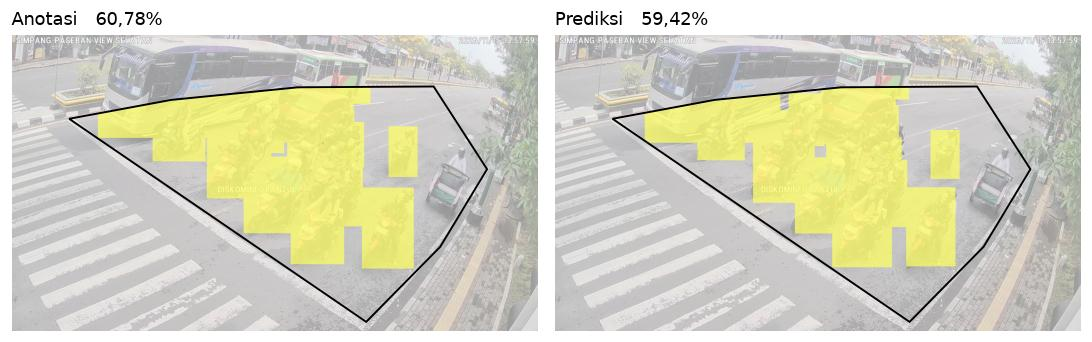

431.966 / 727.028 piksel × 100 = 59,42%
Jumlah sama pada keempat kelas. Selisih luas gabungan: 9.932 piksel.


In [8]:
# Setiap piksel di pusat koordinat diuji terhadap poligon, termasuk piksel pada batas.
def masker_jalan(spec):
    y, x = np.ogrid[:spec["height"], :spec["width"]]
    x, y = x + 0.5, y + 0.5
    dalam = np.zeros((spec["height"], spec["width"]), dtype=bool)
    tepi = np.zeros_like(dalam)
    titik = spec["polygon_xy"]
    for (x1,y1), (x2,y2) in zip(titik, titik[1:] + titik[:1]):
        silang = (x-x1)*(y2-y1) - (y-y1)*(x2-x1)
        tepi |= ((np.abs(silang)<1e-8) & (x>=min(x1,x2)) & (x<=max(x1,x2)) &
                 (y>=min(y1,y2)) & (y<=max(y1,y2)))
        if y1 != y2:
            dalam ^= ((y1>y)!=(y2>y)) & (x < (x2-x1)*(y-y1)/(y2-y1)+x1)
    return dalam | tepi

def gabungan(jalan, kotak):
    isi = np.zeros_like(jalan)
    for p in kotak:
        x1,y1,x2,y2 = p["bbox_xyxy"]
        isi[y1:y2, x1:x2] = True
    return isi & jalan

jalan = masker_jalan(roi)
tertutup = gabungan(jalan, diterima)
assert jalan.any() and jalan.sum() == hasil["summary"]["roi_area_px"]
assert tertutup.sum() == hasil["summary"]["covered_area_px"]
def sidik_masker(a):
    return hashlib.sha256((a.astype("uint8")*255).tobytes()).hexdigest()
assert sidik_masker(tertutup) == hasil["mask_pixels_sha256"]
pembanding = [("Prediksi", tertutup)]
if not FOTO_BARU:
    manual = gabungan(jalan, objek)
    assert manual.sum() == ukur["covered_area_lower_px"]
    pembanding.insert(0, ("Anotasi", manual))
fig, ax = plt.subplots(1, len(pembanding), figsize=(9.6,3.1), squeeze=False)
for a, (nama, msk) in zip(ax[0], pembanding):
    a.imshow(foto, alpha=.48)
    a.imshow(np.ma.masked_where(~msk, msk), cmap="summer", vmin=0, vmax=1, alpha=.74)
    a.add_patch(Polygon(roi["polygon_xy"], fill=False, edgecolor="black", lw=1.2))
    a.set_title(f"{nama}   {angka(100*msk.sum()/jalan.sum())}%", loc="left", fontsize=11)
    a.axis("off")
selesai(fig)
print(f"{angka(tertutup.sum(),0)} / {angka(jalan.sum(),0)} piksel × 100 = {angka(100*tertutup.sum()/jalan.sum())}%")
if not FOTO_BARU:
    print(f"Jumlah sama pada keempat kelas. Selisih luas gabungan: {angka(manual.sum()-tertutup.sum(),0)} piksel.")

## 3. Seberapa dekat hasilnya pada foto uji?

**Deteksi dan klasifikasi** dinilai pada 76 foto dari 55 kelompok adegan. Evaluator memasangkan satu prediksi dengan satu objek acuan bila kelasnya sama dan luas irisan dibagi luas gabungan kotak (*intersection over union*, IoU) minimal 0,50. Prediksi tertentu yang jatuh di zona ambigu dapat dinilai netral sesuai protokol. Presisi membandingkan deteksi benar dengan semua prediksi yang dinilai; *recall* membandingkannya dengan seluruh objek acuan. Macro-F1 memberi bobot sama kepada keempat kelas.

**Jumlah dan cakupan** dinilai pada 31 foto dengan anotasi lengkap. Luas yang diukur adalah persentase piksel ROI yang tertutup gabungan kotak. Dua kotak bertumpuk menyumbang satu hitungan per piksel; kendaraan yang lebih dekat ke kamera dapat menyumbang lebih banyak piksel. Ukuran ini tidak menyatakan kendaraan per kilometer. Nilai uji di bawah dihitung ulang dari hasil v45 yang telah dibekukan. [Protokol dan data pilot](https://github.com/hanafishiddiq/tugas-akhir-pcd/tree/188efdd9c162aa071be6e67d1543273c245bbea2/data/bantul-pilot-v1)

In [9]:
# Deteksi berlebih (FP), objek terlewat (FN), dan deteksi benar (TP) berasal dari evaluator resmi.
deteksi = baris_csv("deteksi_per_kelas.csv")
per_kelas, skor = [], []
for d in deteksi:
    tp, fp, fn = (int(d[k]) for k in ("tp","fp","fn"))
    presisi, recall = tp/(tp+fp), tp/(tp+fn)
    f1 = 2*tp / (2*tp + fp + fn)
    assert np.isclose(f1, float(d["f1"])) and tp+fn == int(d["acuan"])
    skor.append(f1)
    per_kelas.append([d["kelas"], tp+fn, tp, fp, fn, angka(100*presisi), angka(100*recall), angka(100*f1)])
tabel(["Kelas", "Acuan", "TP", "FP", "FN", "Presisi (%)", "Recall (%)", "F1 (%)"], per_kelas)
macro = float(np.mean(skor))
print(f"Macro-F1 validasi terpilih: {angka(100*f1_validasi(45))}% pada {n_split['validation']} foto.")
print(f"Macro-F1 uji resmi: {angka(100*macro)}% pada {n_split['test']} foto / {len(grup['test'])} kelompok.")
print("Hanya 3 dari 8 bus dan 2 dari 6 truk ditemukan dengan posisi dan kelas yang benar.")

Kelas,Acuan,TP,FP,FN,Presisi (%),Recall (%),F1 (%)
mobil,148,130,24,18,"84,42","87,84","86,09"
motor,439,361,60,78,"85,75","82,23","83,95"
bus,8,3,3,5,"50,00","37,50","42,86"
truk,6,2,9,4,"18,18","33,33","23,53"


Macro-F1 validasi terpilih: 85,50% pada 61 foto.
Macro-F1 uji resmi: 59,11% pada 76 foto / 55 kelompok.
Hanya 3 dari 8 bus dan 2 dari 6 truk ditemukan dengan posisi dan kelas yang benar.


Kamera,Foto lengkap,Total tepat,MAE kendaraan/foto,MAE cakupan (poin)
Paseban Selatan,12,8,"0,67","1,86"
Paseban Barat,11,8,"0,27","6,63"
Bejen Barat,8,6,"0,38","0,93"
Gabungan,31,22,"0,45","3,32"


MAE per jenis (kendaraan/foto): mobil 0,13 · motor 0,32 · bus 0,06 · truk 0,06


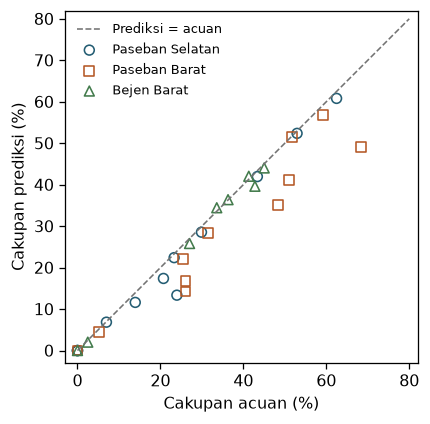

22/31 foto memiliki jumlah total tepat. Lima foto kosong bertumpuk di titik (0, 0).
Di Paseban Barat, ketepatan jumlah tetap menyisakan MAE cakupan 6,63 poin.


In [10]:
# MAE memberi bobot sama pada tiap foto. Selisih luas dinyatakan dalam poin persentase.
uji = baris_csv("perbandingan_31.csv")
kamera = sorted({d["camera"] for d in uji})
def vektor(k, data):
    return np.array([int(d[k]) for d in data])
def cakupan(k, data):
    return 100*vektor(k+"_px", data)/vektor("roi_px", data)
def galat(data):
    jumlah = vektor("total_v45", data) - vektor("total_acuan", data)
    luas = cakupan("v45", data) - cakupan("acuan", data)
    return np.mean(abs(jumlah)), np.mean(abs(luas)), int(np.sum(jumlah==0))

laporan = []
for kode in [*kamera, None]:
    data = [d for d in uji if kode is None or d["camera"] == kode]
    n, luas, tepat = galat(data)
    laporan.append([nama_kamera(kode) if kode else "Gabungan", len(data), tepat, angka(n), angka(luas)])
tabel(["Kamera", "Foto lengkap", "Total tepat", "MAE kendaraan/foto", "MAE cakupan (poin)"], laporan)
mae_kelas = [np.mean(abs(vektor(k+"_v45",uji)-vektor(k+"_acuan",uji))) for k in KELAS]
print("MAE per jenis (kendaraan/foto):", " · ".join(f"{k} {angka(e)}" for k,e in zip(KELAS,mae_kelas)))
mae_n, mae_d, benar = galat(uji)
beku = next(x for x in baris_csv("hitungan_dan_cakupan.csv") if x["kelompok"]=="semua")
assert np.allclose([mae_n,mae_d], [float(beku["mae_total"]),float(beku["mae_cakupan_pp"])])
fig, ax = plt.subplots(figsize=(6.1,3.8))
ax.plot([0,80],[0,80], ls="--", lw=1, color="0.45", label="Prediksi = acuan")
for k, simbol, tinta in zip(kamera, ["o","s","^"], ["#245d73","#b45725","#437b4c"]):
    subset = [d for d in uji if d["camera"]==k]
    ax.scatter(cakupan("acuan",subset), cakupan("v45",subset), marker=simbol, s=38,
               facecolors="none", edgecolors=tinta, label=nama_kamera(k))
ax.set(xlabel="Cakupan acuan (%)", ylabel="Cakupan prediksi (%)", xlim=(-3,82), ylim=(-3,82), aspect="equal")
ax.legend(fontsize=8, loc="upper left", frameon=False)
selesai(fig)
print(f"{benar}/{len(uji)} foto memiliki jumlah total tepat. Lima foto kosong bertumpuk di titik (0, 0).")
print("Di Paseban Barat, ketepatan jumlah tetap menyisakan MAE cakupan 6,63 poin.")

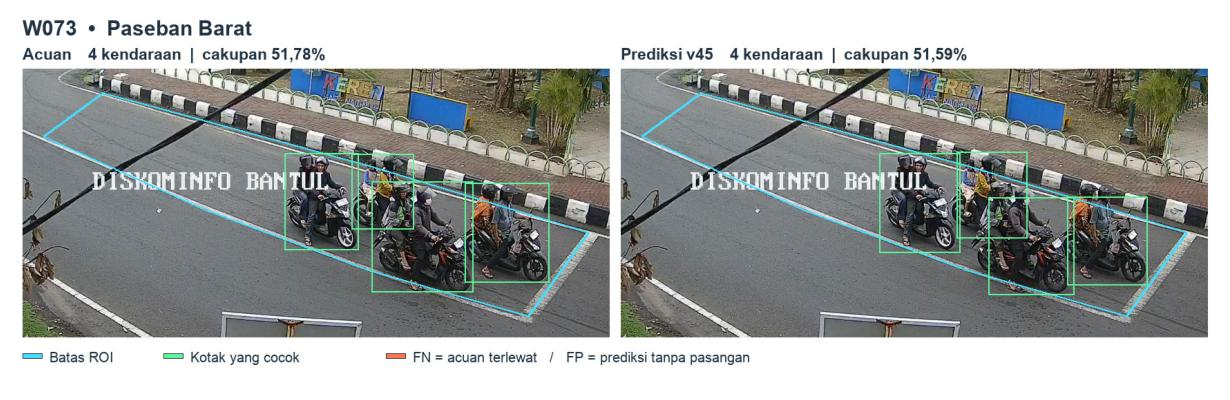

W073 · jumlah 4 → 4 · cakupan 51,78% → 51,59%
Keempat motor memiliki pasangan yang benar; selisih luas bersih hanya 255 piksel.


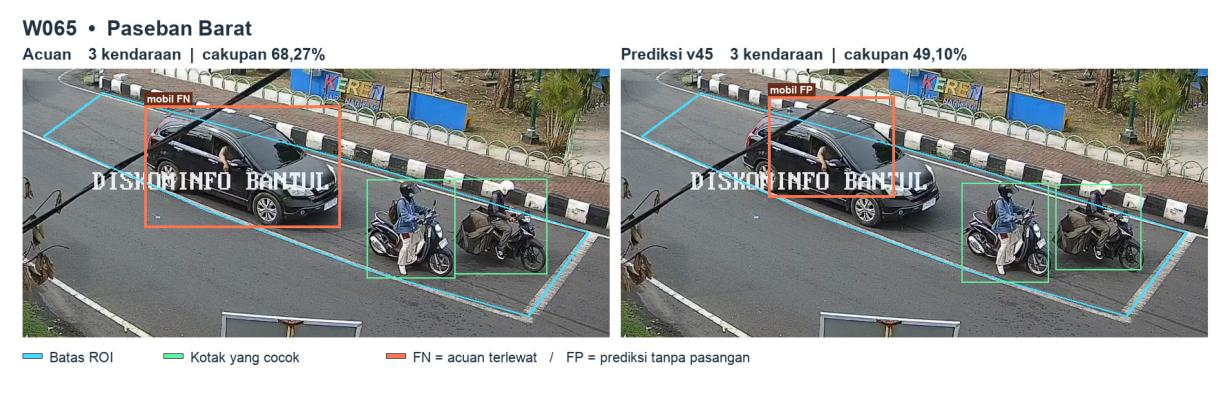

W065 · jumlah 3 → 3 · cakupan 68,27% → 49,10%
Kotak mobil terlalu pendek (IoU 0,463). Jumlah tetap tepat, tetapi cakupan meleset 19,17 poin.


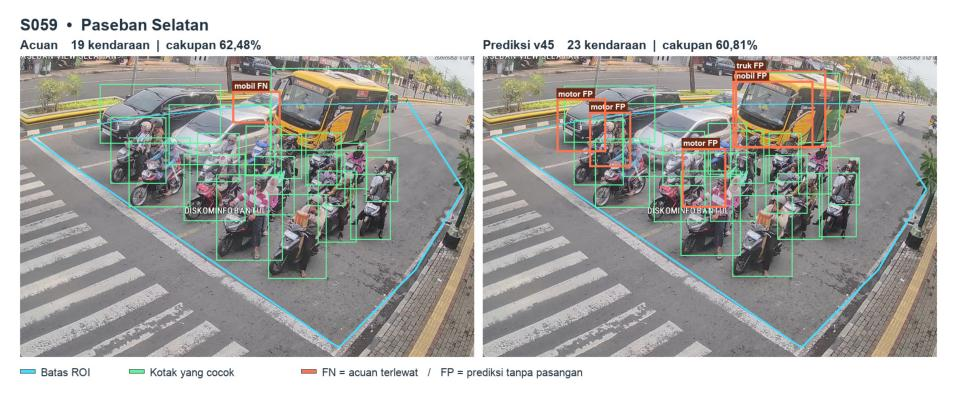

S059 · jumlah 19 → 23 · cakupan 62,48% → 60,81%
Lima kotak berlebih, satu mobil terlewat. Kotak berlebih banyak bertumpuk dengan kotak yang sudah cocok.


In [11]:
# Bandingkan dua foto dengan galat yang berbeda. Panel asli menempatkan acuan di kiri, prediksi di kanan.
kasus = {d["image_id"]:d for d in uji}
id_luas = max(kasus, key=lambda i: float(kasus[i]["galat_absolut_pp"]))
id_jumlah = max(kasus, key=lambda i: int(kasus[i]["galat_absolut_total"]))
assert (id_luas, id_jumlah) == ("W065","S059")
for nama in ["W073", id_luas, id_jumlah]:
    d = kasus[nama]
    fig, ax = plt.subplots(figsize=(10.8,3.65))
    ax.imshow(gambar(nama+".jpg")); ax.axis("off")
    selesai(fig)
    print(f"{nama} · jumlah {d['total_acuan']} → {d['total_v45']} · cakupan "
          f"{angka(float(d['cakupan_acuan_persen']))}% → {angka(float(d['cakupan_v45_persen']))}%")
    if nama == "W073":
        print("Keempat motor memiliki pasangan yang benar; selisih luas bersih hanya 255 piksel.")
    elif nama == "W065":
        print("Kotak mobil terlalu pendek (IoU 0,463). Jumlah tetap tepat, tetapi cakupan meleset 19,17 poin.")
    elif nama == "S059":
        print("Lima kotak berlebih, satu mobil terlewat. Kotak berlebih banyak bertumpuk dengan kotak yang sudah cocok.")

In [12]:
# Cek semua masker dan hitungan secara mandiri dari kotak. Dalam mode inferensi, uji juga program rilis.
if MODE == "inferensi":
    with tempfile.TemporaryDirectory() as direktori:
        laporan_uji = Path(direktori)/"hasil_uji.json"
        subprocess.run([sys.executable, "-X", "utf8", str(PAKET/"uji_contoh.py"), "--laporan", str(laporan_uji)],
                       check=True, capture_output=True)
        nyata = json.loads(laporan_uji.read_bytes())
        assert nyata["lulus"] and {v["contoh"] for v in nyata["hasil"]} == set(acuan_demo)
        for v in nyata["hasil"]:
            assert all(v[k] == nilai for k,nilai in acuan_demo[v["contoh"]]["summary"].items())

cek = []
for nama, rekam in acuan_demo.items():
    jalan_uji = masker_jalan(rois[rekam["camera_id"]])
    kotak = [p for p in rekam["predictions"] if p["roi_membership"]=="inside"]
    area = gabungan(jalan_uji,kotak)
    jumlah = Counter(p["class_name"] for p in kotak)
    assert all(jumlah[k]==rekam["summary"]["count_by_class"][k] for k in KELAS)
    assert sidik_masker(area) == rekam["mask_pixels_sha256"]
    cek.append([nama, nama_kamera(rekam["camera_id"]), len(kotak), angka(100*area.sum()/jalan_uji.sum())+"%", "Cocok"])
tabel(["Foto validasi", "Kamera", "Jumlah", "Cakupan", "Hash piksel masker"], cek)
waktu = baris_csv("waktu_76.csv")
detik = [float(x["detik"]) for x in waktu]
assert len(detik) == n_split["test"] and len({d["image_id"] for d in waktu}) == len(detik)
print("Pemeriksaan:", "inferensi ulang empat foto dengan pemeriksa resmi + rekonstruksi masker" if MODE=="inferensi"
      else "rekonstruksi dari prediksi beku pada empat foto")
print(f"Catatan waktu uji resmi ({len(detik)} foto): median {angka(np.median(detik))} detik, P90 {angka(np.percentile(detik,90))} detik.")
print("Pengukuran pada mesin uji, satu thread komputasi, sesudah gambar dan model dimuat; di luar baca/tulis dan gambar overlay.")

Foto validasi,Kamera,Jumlah,Cakupan,Hash piksel masker
S033,Paseban Selatan,16,"59,42%",Cocok
W046,Paseban Barat,3,"33,09%",Cocok
NB006,Bejen Barat,13,"46,77%",Cocok
W041,Paseban Barat,0,"0,00%",Cocok


Pemeriksaan: inferensi ulang empat foto dengan pemeriksa resmi + rekonstruksi masker
Catatan waktu uji resmi (76 foto): median 8,10 detik, P90 20,94 detik.
Pengukuran pada mesin uji, satu thread komputasi, sesudah gambar dan model dimuat; di luar baca/tulis dan gambar overlay.


## 4. Kesimpulan

Pada S033, acuan dan model sama-sama menghitung **1 mobil, 13 motor, 2 bus, dan 0 truk**. Selisih 9.932 piksel tetap muncul pada luas gabungan. Pada W065, kotak satu mobil yang terlalu pendek membuat galat cakupan mencapai 19,17 poin meskipun jumlahnya tepat. Karena itu, hitungan dan luas perlu dilaporkan bersama.

Pada tiga sudut CCTV yang diuji, dua sasaran gabungan tercapai: **0,45 kendaraan per foto** terhadap batas 1, dan **3,32 poin persentase** terhadap batas 5. Dua sasaran deteksi belum tercapai: macro-F1 uji **59,11%** terhadap target 85%, dan F1 bus maupun truk berada di bawah target 75% per kelas. Keterwakilan kendaraan berat rendah. Evaluasi hitungan dan luas berlaku untuk 31 foto dengan acuan lengkap; sudut kamera baru, antrean yang lebih padat, dan kesepakatan antarpenilai manusia memerlukan pengujian tersendiri.

**Bahan pemeriksaan** · [Paper IEEE enam halaman](https://github.com/hanafishiddiq/tugas-akhir-pcd/blob/main/paper/paper.pdf) · [Tabel dan gambar uji](https://github.com/hanafishiddiq/tugas-akhir-pcd/tree/188efdd9c162aa071be6e67d1543273c245bbea2/evaluasi) · [Paket demo v45](https://github.com/hanafishiddiq/tugas-akhir-pcd/releases/tag/v45.1)

Foto CCTV bersumber dari Pemerintah Kabupaten Bantul / Diskominfo Bantul. Kotak, batas ROI, arsiran, serta panel perbandingan ditambahkan oleh tim. Salinan data ringkas tertanam di notebook. Daftar berkas asal dan SHA-256 dapat dibaca melalui `baca("asal.json")`.